<a href="https://colab.research.google.com/github/Shubham-chaudhary07/Colab_work_ML/blob/main/GDG_hiring_task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Student Dropout Prediction
This notebook predicts student dropout based on specific enrollment and academic features using a Logistic Regression model.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Loading the data
file_path = '/content/dataset.csv'
df = pd.read_csv(file_path)

# Selecting columns
columns_to_keep = [
    'Age at enrollment',
    'Course',
    'Scholarship holder',
    'Tuition fees up to date',
    'Curricular units 1st sem (grade)',
    'Target'
]


df = df[columns_to_keep]


df['Target'] = df['Target'].apply(lambda x: 1 if str(x).strip() == 'Dropout' else 0)

display(df.head())

,Age at enrollment,Course,Scholarship holder,Tuition fees up to date,Curricular units 1st sem (grade),Target
0,20,2,0,1,0.000000,1
1,19,11,0,0,14.000000,0
2,19,5,0,0,0.000000,1
3,20,15,0,1,13.428571,0
4,45,3,0,1,12.333333,0


In [11]:

print("Missing values:\n", df.isnull().sum())


df = df[df['Age at enrollment'] > 0]
df = df[df['Curricular units 1st sem (grade)'] >= 0]


df = pd.get_dummies(df, columns=['Course'], drop_first=True)

print("Preprocessing complete. Shape:", df.shape)

Missing values:
 Age at enrollment                   0
Course                              0
Scholarship holder                  0
Tuition fees up to date             0
Curricular units 1st sem (grade)    0
Target                              0
dtype: int64
Preprocessing complete. Shape: (4424, 21)


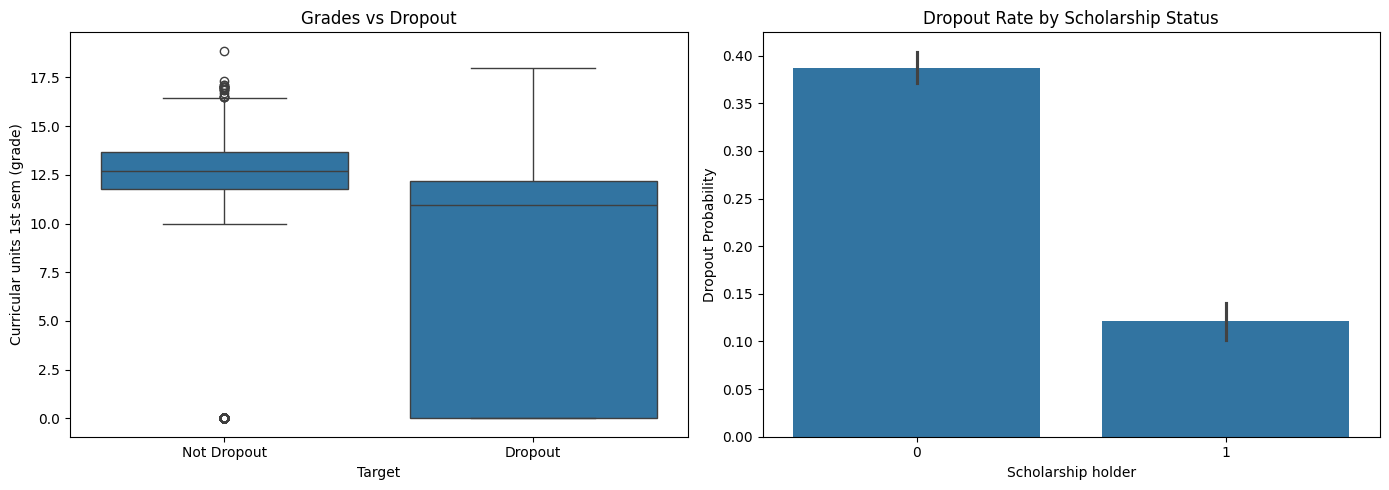

In [12]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x='Target', y='Curricular units 1st sem (grade)', data=df)
plt.title('Grades vs Dropout')
plt.xticks([0, 1], ['Not Dropout', 'Dropout'])

plt.subplot(1, 2, 2)
sns.barplot(x='Scholarship holder', y='Target', data=df)
plt.title('Dropout Rate by Scholarship Status')
plt.ylabel('Dropout Probability')

plt.tight_layout()
plt.show()

Accuracy: 81.02%


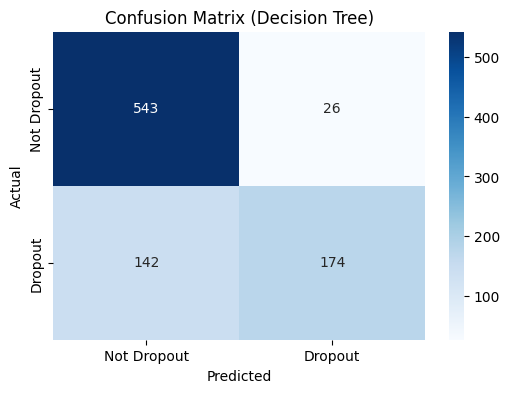

In [15]:
from sklearn.tree import DecisionTreeClassifier

X = df.drop('Target', axis=1)
y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

# Evaluation
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Accuracy: {acc:.2%}")
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Dropout', 'Dropout'], yticklabels=['Not Dropout', 'Dropout'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Decision Tree)')
plt.show()